# Laboratory Partial

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Exercise 1 (1 point)

A scientist studies how a chemical reaction rate depends on temperature. The Arrhenius equation gives the rate constant $k$ as:

$$k = A\, e^{-\frac{E_a}{RT}}$$

where $A$ is the pre-exponential factor, $E_a$ the activation energy, and $R = 8.3145$ J/(mol·K) the universal gas constant.

Experimental data:

$$\{(k, T)\} = \{(0.0021, 300\,\text{K}),\,(0.0063, 320\,\text{K}),\,(0.0192, 340\,\text{K}),\,(0.0580, 360\,\text{K}),\,(0.1650, 380\,\text{K})\}$$

Estimate $A$ and $E_a$ using:

- Direct pseudoinverse (0.5 points)
- Pseudoinverse via SVD (0.5 points)

In [2]:
#  Experimental data
R = 8.3145

k = np.array([0.0021, 0.0063, 0.0192, 0.0580, 0.1650])
T = np.array([300, 320, 340, 360, 380])

y = np.log(k)
X = np.column_stack([np.ones(len(T)), 1.0 / T])

In [3]:
# Direct pseudoinverse
from utils import print_results

pseudoinv = np.linalg.inv(X.T @ X) @ X.T
theta = pseudoinv @ y

A = np.exp(theta[0])
E_a = -theta[1] * R

labels = ["X", "X_inv", "Theta", "results", "A", "E_a"]
values = [X, pseudoinv, theta, None, A, E_a]
print_results(labels, values)


------------------------------------------------------------
X =
[[1.         0.00333333]
 [1.         0.003125  ]
 [1.         0.00294118]
 [1.         0.00277778]
 [1.         0.00263158]]

------------------------------------------------------------
X_inv =
[[-3.37289809e+00 -1.36957773e+00  3.98057885e-01  1.96928954e+00
   3.37512839e+00]
 [ 1.20633746e+03  5.29945261e+02 -6.68713857e+01 -5.97375071e+02
  -1.07203626e+03]]

------------------------------------------------------------
Theta =
[   14.4746247  -6226.54772074]

========== RESULTS ============
A = 1933079.134407081
E_a = 51770.631024090944


In [4]:
# Pseudoinverse via SVD
X_TX = X.T @ X

eigenvals, eigenvecs = np.linalg.eigh(X_TX)

V = eigenvecs.copy()
delta = np.diag(np.sqrt(eigenvals))
delta_inv = np.linalg.inv(delta)
U = X @ V @ delta_inv

#  check wether the decomposition is correct:
print("="*40, "\n", "Correct decomposition? ", np.allclose(X, U @ delta @ V.T), sep="")

#  now for the pseudoinverse:
pseudoinv2 = V @ delta_inv @ U.T
print("="*40, "\n", "Same pseudoinverse?", np.allclose(pseudoinv, pseudoinv2), sep="")

theta2 = pseudoinv2 @ y
A2 = np.exp(theta2[0])
E_a2 = -theta2[1] * R

values = [X, pseudoinv2, theta2, None, A2, E_a2]
print_results(labels, values)

Correct decomposition? True
Same pseudoinverse?True
------------------------------------------------------------
X =
[[1.         0.00333333]
 [1.         0.003125  ]
 [1.         0.00294118]
 [1.         0.00277778]
 [1.         0.00263158]]

------------------------------------------------------------
X_inv =
[[-3.37289809e+00 -1.36957773e+00  3.98057885e-01  1.96928954e+00
   3.37512839e+00]
 [ 1.20633746e+03  5.29945261e+02 -6.68713857e+01 -5.97375071e+02
  -1.07203626e+03]]

------------------------------------------------------------
Theta =
[   14.4746247  -6226.54772074]

========== RESULTS ============
A = 1933079.1344059545
E_a = 51770.63102408948


# Exercise 2 (2.5 points)

You are studying two species of mice: **Field Mice** and **House Mice**, characterised by:

- **Ear Size** (mm)
- **Tail Length** (cm)

Training data:

| Mouse | Ear Size (mm) | Tail Length (cm) | Species     |
|------:|--------------:|-----------------:|:------------|
|     1 |            25 |             10.0 | Field Mouse |
|     3 |            24 |              9.5 | Field Mouse |
|     4 |            12 |              5.0 | House Mouse |
|     6 |            11 |              4.5 | House Mouse |

Validation data:

| Mouse | Ear Size (mm) | Tail Length (cm) | Species     |
|------:|--------------:|-----------------:|:------------|
|     5 |            13 |              6.0 | House Mouse |
|     2 |            27 |             11.0 | Field Mouse |

In [ ]:
#  Training data
X_train = np.array([[25, 10.0, 1], [24, 9.5, 1], [12, 5.0, 1], [11, 4.5, 1]]) #  [Ear Size, Tail Length, Bias]
y_train = np.array([1, 1, -1, -1])  # Field=+1, House=-1
#  Validation data
X_val = np.array([[13, 6.0, 1], [27, 11.0, 1]])
y_val = np.array([-1, 1])

1. Plot the training and validation data. (0.25 points)

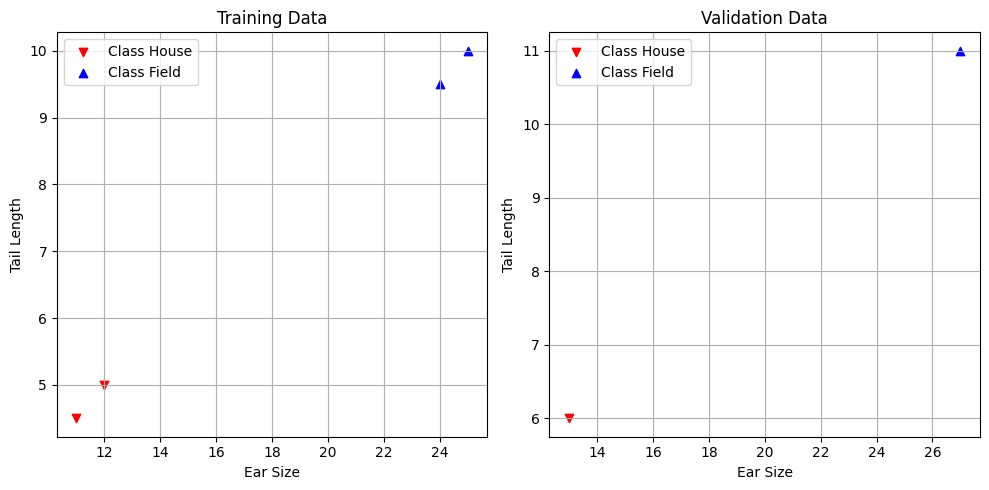

In [ ]:
def create_plot(data_label, X, y, axes):
    for label, marker, color in zip([-1, 1], ["v", "^"], ["red", "blue"]):
        species = "Field" if label == 1 else "House"
        axes.scatter(
            X[y == label, 0],
            X[y == label, 1], 
            label=f"Class {species}",
            marker=marker,
            color=color,
        )
    axes.set_xlabel("Ear Size")
    axes.set_ylabel("Tail Length")
    axes.set_title(data_label)
    axes.legend()
    axes.grid(True)

X_train_plot = X_train[:, :2] #  the bias is not plotted, only the variables measured
X_val_plot = X_val[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

create_plot("Training Data", X_train_plot, y_train, axes[0])
create_plot("Validation Data", X_val_plot, y_val, axes[1])

plt.tight_layout()
plt.show()

2. Complete the vectorised Perceptron Learning rule below. *Vectorised* means no inner loops over samples. (1 point)

In [7]:
#  made a function to reuse the same setup later:
def perceptron(X, y, learning_rate = 1, max_iter = 100, verbose = 0):
    w = np.zeros(3)
    mistake = True
    epoch = 0
    while mistake:
        if epoch > max_iter:
            print(f"Couldn't converge in {max_iter} iterations.")
            return w
        # your code here
        if verbose and epoch % 10 == 0:
            print("Epoch", epoch)
        missclassified = y * (X @ w) <= 0
        if any(missclassified):
            w += learning_rate * np.sum((y[missclassified][:, np.newaxis] * X[missclassified]), axis = 0)
        else:
            mistake = False
        epoch +=1
    print(f"Converged in {epoch} steps.")
    return w

w = perceptron(X = X_train, y = y_train, verbose=1)
print("w =", w)

Epoch 0
Epoch 10
Epoch 20
Epoch 30
Epoch 40
Epoch 50
Epoch 60
Epoch 70
Epoch 80
Converged in 81 steps.
w = [  9.  -15.5 -58. ]


In [8]:
y_val_pred = np.sign(X_val @ w)

pd.DataFrame({
    "Mouse": [5, 2],
    "Predicted": np.where(y_val_pred == 1, "Field Mouse", "House Mouse"),
    "True":      ["House Mouse", "Field Mouse"]
})

,Mouse,Predicted,True
0,5,House Mouse,House Mouse
1,2,Field Mouse,Field Mouse


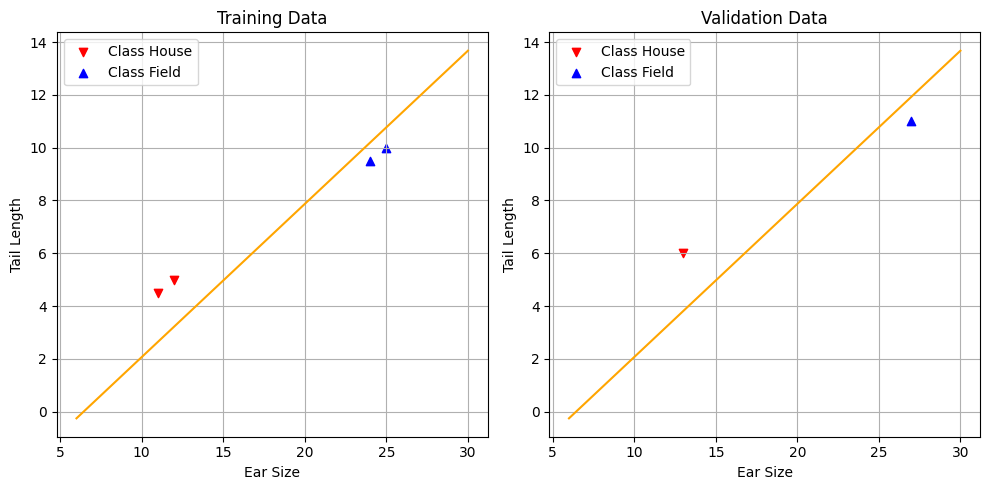

In [9]:
#  Aditional: plot the hyperplane
x_values = np.linspace(X_train[:, 0].min() - 5, X_train[:, 0].max() + 5)
y_values = -(w[0] / w[1]) * x_values - (w[2] / w[1])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

create_plot("Training Data", X_train_plot, y_train, axes[0])
create_plot("Validation Data", X_val_plot, y_val, axes[1])

for i in range(2):
    axes[i].plot(x_values, y_values, color="orange", label="Decision boundary")

plt.tight_layout()
plt.show()

3. Is the vectorised Perceptron appropriate for this problem? (0.25 points)

*Yes, because the data is linearly separable.*

4. Compute the margin $\gamma$ of your classifier. Check that the number of mistakes satisfies the convergence theorem bound. (0.5 points)

In [11]:
functional_margin = y_train * np.dot(X_train, w)
weight_norm = np.linalg.norm(w[:-1])
geometric_margin = functional_margin / weight_norm

print("Functional margin of the classifier:", functional_margin)
print("Geometrical margin of the classifier:", geometric_margin)

Functional margin of the classifier: [12.   10.75 27.5  28.75]
Geometrical margin of the classifier: [0.66951402 0.59977298 1.53430297 1.60404401]


5. Normalise the data and re-run. Does convergence change? Why? (0.5 points)

In [12]:
#  no norm
print("Running perceptron without normalising...")
w_z = perceptron(X_train, y_train, max_iter= 1000)
print("=" * 60)

#  min_max norm
X_train_norm = X_train.copy()
X_min = X_train[:, :-1].min(axis=0)
X_max = X_train[:, :-1].max(axis=0)
denom = X_max - X_min
denom[denom == 0] = 1 #  avoid div by 0
X_train_norm[:, :-1] = (X_train[:, :-1] - X_min) / denom

print("Running perceptron with min-max normalization...")
w_m = perceptron(X_train_norm, y_train, max_iter= 1000)
print("=" * 60)

#  z_score
X_train_std = X_train.copy()
mean = X_train[:, :-1].mean(axis=0)
std  = X_train[:, :-1].std(axis=0)
std[std == 0] = 1 #  avoid div by 0
X_train_std[:, :-1] = (X_train[:, :-1] - mean) / std

print("Running perceptron with z-score standarization...")
w_z = perceptron(X_train_std, y_train, max_iter= 1000)

Running perceptron without normalising...
Converged in 81 steps.
Running perceptron with min-max normalization...
Converged in 3 steps.
Running perceptron with z-score standarization...
Converged in 2 steps.


*Convergence is faster (from 81 iterations to 2-3 iterations). This is normal due to to the different scales of the data (mm for Ear Size, and cm for Tail Length). Also, it takes less steps because the initial w vector is [0. 0. 0.], and the original data ranges from 11 to 25 for ear sizes, and 4.5 to 10 for tail lengths. That is why standarization with z-score gives a better result, because, although both methods bring all values near the 0 (0 to 1 for min-max and -1 to 1 for z-score), with z-score the values are centered around the 0, meaning the model just has to adjust the angle of the hyperplane (since, as we mentioned earlier, we initialize w to [0. 0. 0.]).*

# Exercise 3 (2.5 points)

A weather station records the number of strong wind gusts (above 50 km/h) per day. You want to predict tomorrow's gust count based on today's observations:

- `Today_Wind`: mean wind speed today (km/h)
- `Today_Temp_Effect`: temperature-driven wind contribution today (km/h)
- `Local_Pressure`: local pressure-driven wind contribution (km/h)
- `Prev_Day_Wind`: mean wind speed yesterday (km/h)

In [ ]:
train_data = pd.DataFrame({
    'Today_Wind':        [12.331344, 14.190451, 11.061576, 14.765765, 14.465941,
                           9.693871, 12.531540, 13.949093, 12.392729, 11.970554,
                          13.940820, 12.685564, 13.464540, 12.294099, 11.141531,
                          14.712357, 11.082903, 10.657860, 12.078670, 15.183309],
    'Today_Temp_Effect': [26.44320, 25.76959, 22.69044, 21.47019, 21.09764,
                          19.52647, 21.96041, 16.67302, 33.84478, 29.03981,
                          17.38446, 20.98558, 20.66672, 26.89983, 22.58315,
                          24.26659, 22.85727, 22.78565, 29.84301, 21.87115],
    'Local_Pressure':    [19.549412, 10.353742, 16.753841, 15.371563, 15.647825,
                          16.138918, 13.493030, 14.000378, 11.944274, 11.784626,
                          15.910586, 16.344629, 15.159013, 17.766802, 21.150254,
                          13.526907,  8.072493, 18.017216, 12.872398, 12.935974],
    'Prev_Day_Wind':     [11.95067, 13.79914, 11.43453, 14.50574, 14.63289,
                          10.23066, 12.83317, 14.27677, 13.07936, 12.17283,
                          14.95006, 12.81509, 13.60544, 12.70020, 11.08903,
                          14.99588, 11.50464, 10.32966, 11.32565, 15.45284],
    'Gusts_Tomorrow':    [27, 18, 24, 27, 20, 21, 20, 18, 21, 19,
                          21, 19, 23, 29, 21, 24, 19, 23, 20, 22]
})
#  gusts (variable a predecir) -> recuento de rafágas de viento de mañana

valid_data = pd.DataFrame({
    'Today_Wind':        [14.14757, 14.55768, 13.96884, 14.85350, 12.76532,
                          13.18745, 12.84877, 12.84736, 11.27203, 10.25976],
    'Today_Temp_Effect': [22.77486, 19.07548, 14.66029, 21.09887, 27.59498,
                          20.12327, 26.03982, 14.91059, 22.72219, 25.59704],
    'Local_Pressure':    [15.90346, 15.31703, 13.07788, 12.45089, 11.92761,
                          15.35294, 12.15758, 13.52833, 14.23172, 20.53159],
    'Prev_Day_Wind':     [10.535997, 14.876336, 13.670299,  9.200209, 12.850680,
                          22.209957, 15.429354, 13.218108,  8.910818, -1.583915],
    'Gusts_Tomorrow':    [23, 23, 18, 23, 21, 24, 19, 16, 27, 24]
})

print(train_data.head())
print(valid_data.head())

   Today_Wind  Today_Temp_Effect  Local_Pressure  Prev_Day_Wind  \
0   12.331344           26.44320       19.549412       11.95067   
1   14.190451           25.76959       10.353742       13.79914   
2   11.061576           22.69044       16.753841       11.43453   
3   14.765765           21.47019       15.371563       14.50574   
4   14.465941           21.09764       15.647825       14.63289   

   Gusts_Tomorrow  
0              27  
1              18  
2              24  
3              27  
4              20  
   Today_Wind  Today_Temp_Effect  Local_Pressure  Prev_Day_Wind  \
0    14.14757           22.77486        15.90346      10.535997   
1    14.55768           19.07548        15.31703      14.876336   
2    13.96884           14.66029        13.07788      13.670299   
3    14.85350           21.09887        12.45089       9.200209   
4    12.76532           27.59498        11.92761      12.850680   

   Gusts_Tomorrow  
0              23  
1              23  
2             

1. Fit a suitable model to predict `Gusts_Tomorrow`. Report training and validation errors.
2. How can you improve generalisation? Choose and justify the best hyperparameters.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X_train = train_data.drop('Gusts_Tomorrow', axis=1)
X_val = valid_data.drop('Gusts_Tomorrow', axis=1)

y_train = train_data['Gusts_Tomorrow']
y_val = valid_data['Gusts_Tomorrow']

model = LinearRegression()

model.fit(X_train, y_train)

train_preds = model.predict(X_train)
val_preds = model.predict(X_val)

print("Training MSE:", mean_squared_error(y_train, train_preds))
print("Validation MSE:", mean_squared_error(y_val, val_preds))

Training MSE: 5.433549394017053
Validation MSE: 20.782880379736774


*As we can see, a regular linear model doesn't provide good generalization with our data, since we got a validation MSE 4 times bigger than the training MSE; this could indicate overfitting. Next, we'll try a regularized model. Before doing that though, we observed a negative value in the validation data !!!!!!!!!!!!(we have yet to decide what to do)!!!!!!!!!!!.*

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import Ridge, Lasso

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

param_grid = [
    {
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model': [Ridge(max_iter=10000), Lasso(max_iter=10000)],
        'model__alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 15.0, 20.0, 30.0, 40.0, 50.0, 100.0]
    }
]

grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=5, 
    scoring='neg_mean_squared_error' 
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

print("Best Hyperparameters:", grid_search.best_params_)
print("Training MSE:", mean_squared_error(y_train, train_preds))
print("Validation MSE:", mean_squared_error(y_val, val_preds))

Best Hyperparameters: {'model': Ridge(max_iter=10000), 'model__alpha': 30.0, 'scaler': 'passthrough'}
Training MSE: 5.632241913665106
Validation MSE: 7.887324428870107


*After performing a grid search to choose the best regularized regression model, the best scaling method, and the best penalty term (alpha), we concluded that the best model is a Ridge regression with alpha = 30.0 and without scaling the data. Now, the difference between training MSE and validation MSE is aproximately 2 units, with a cost of 0.2 units more of training error (which is even negligible).*

# Exercise 4 (4 points)

Predict whether a patient will experience disorientation within 12 hours of receiving a 100 mg dose of a new medication.

Predictors: body fat, meat in diet, stress level, blood oxygen, blood sugar.

In [33]:
training_data = pd.DataFrame({
    'fat':   [15.22442, 28.51168,  6.13891, 18.20264, 16.41537, 19.31584,  7.57312, 27.49562,  6.05149, 13.19802, 28.86259, 21.01267, 21.39264, 19.85355, 12.22899, 29.07561, 27.55748, 24.88669, 16.94490, 23.96149, 12.95453, 10.79064, 15.34311,  8.81112,  8.47015, 10.82585, 16.64906,  6.14578, 10.16328,  7.37102, 15.99579, 23.86188,  5.01562, 10.50297, 14.49541, 13.79495,  7.77839, 11.09049,  7.57162,  9.37632,  8.26739, 13.00933,  7.33987, 16.66948, 19.99972, 17.21533, 28.86185, 17.07256,  8.67737, 28.38250,  8.55736, 18.73212, 12.69300, 14.23722,  8.85506,  7.27610, 20.48141, 21.82498, 23.42694, 24.65704, 15.23687, 26.06823, 11.14309, 11.16122,  7.77741, 14.74986, 21.24963, 18.34220, 10.52757, 15.31865, 11.64217, 23.66420, 21.70712, 12.81120, 22.70726, 17.03225, 11.62582, 27.54686, 13.03707, 29.64102,  8.80867, 19.32168, 10.96815, 20.03414, 12.20598,  9.26613,  9.30429, 17.05107, 22.52133, 23.20986, 27.89209, 15.71054,  6.46196, 20.82638, 24.63229, 15.10998, 16.78941, 28.14270, 17.57033,  5.15752,  9.10528, 21.22045, 23.96483,  6.62321,  6.36573, 12.44354, 27.01101, 25.41515, 29.55351,  7.58999, 24.97079, 24.61438,  5.23575, 23.23477, 20.75330,  5.20539, 17.30733],
    'meat':  [121.7750, 141.3636,  94.5035, 184.0134, 135.3303, 148.9152, 233.9748,  92.9359, 242.5512,  65.6625, 253.7704, 128.0282, 179.7012,  56.3817, 297.2696, 284.7846, 221.9019, 254.1195, 234.7579, 137.1799, 183.8853, 118.6363, 258.0269, 238.2775, 291.0381,  70.3666, 263.5912, 131.8993, 196.7397, 282.3377, 271.2832, 188.3285, 155.8659, 227.2595, 153.3264, 191.6835, 172.5159, 269.6685, 268.4875, 195.6849, 181.6475,  72.0908, 134.3738, 273.5837, 109.3074, 106.4546, 129.6236,  93.4960, 143.5423, 207.4364, 245.4558, 272.9740, 243.8519,  60.5270, 118.4378, 262.6169, 239.7838, 164.4804, 232.4079, 238.0094, 249.7059,  72.5805, 125.1294, 191.7799, 234.1551, 264.3619,  79.3328,  68.7392,  89.2920, 211.7643,  93.3794, 120.7506, 155.1087, 228.6887, 257.8055, 187.6542, 180.5839, 113.4552, 208.7001, 184.8902, 157.1533, 138.9404, 261.2334,  55.7861, 144.1111,  96.4683, 157.2351, 207.6934, 146.1142, 235.6348,  55.7137, 268.7206, 281.1197, 199.3384, 172.4593, 272.0929,  59.1761, 178.4453, 213.3570, 253.2783, 251.8748, 252.1530, 114.7003, 100.8543, 120.7832, 283.4241, 172.3570, 151.9077,  75.9279, 120.1413, 114.8112, 167.6705, 141.4614,  61.7484, 115.6991, 169.4555, 216.9101],
    'stress':[16.01848, 84.77392, 47.78868, 77.36921, 44.05331, 50.69977,  1.91910, 77.36860, 64.14626, 46.84321, 27.92238, 58.55656, 81.12373, 45.54890, 26.88034, 23.12309, 54.32329, 13.02881, 54.79943, 14.92442, 42.68856, 44.77301, 45.68868, 24.24571,  7.58608, 39.12951,  1.31082, 70.88554, 27.64399, 17.30430, 56.19632, 78.84094, 80.04764, 62.89278, 27.14090, 41.98642, 35.54347, 39.23313, 75.93357, 48.01264, 80.62479, 73.87485, 62.45530, 28.86901, 80.09179, 21.70480, 74.42385, 86.66537, 66.05323,  7.22866, 24.43082, 42.18101, 71.86118, 13.83901, 93.10996, 56.83380, 54.02562, 70.29795, 56.77484, 28.80103, 40.53639, 21.71838, 32.82387, 91.89548, 52.87654, 37.19788, 45.92408,  7.24691, 28.69576, 14.94125, 97.24320, 91.63057, 21.66621, 21.05232, 67.90228, 13.49964, 38.74983, 59.42730, 55.50781, 44.94114, 96.85509, 38.51986, 85.85914, 48.90915, 15.76628, 78.53486, 54.21883, 41.65473, 81.36684, 11.16880, 53.09357, 27.75601, 58.87063, 44.02418, 86.59671, 24.45707, 98.15432, 24.87264, 97.28035, 72.52280, 56.61824, 39.21965, 20.20875, 73.55584, 34.61270, 81.57680, 84.81077, 30.33252, 77.05970, 73.34485, 56.90488,  2.62808, 48.61272, 83.66601, 72.86645, 13.65023,  9.96219],
    'oxygen':[83.6896, 90.8647, 86.6990, 87.5413, 87.9056, 76.6831, 82.6051, 82.5995, 81.4134, 82.6705, 75.7428, 91.9361, 91.9372, 82.5524, 89.3152, 95.0033, 90.8430, 82.4272, 77.5004, 81.2130, 97.9481, 84.2903, 79.9335, 90.2899, 78.3200, 71.5857, 82.7728, 99.0940, 79.5550, 79.3722, 95.9518, 78.2977, 80.7598, 92.3828, 70.8888, 77.6988, 84.9405, 89.6007, 94.3718, 80.4590, 93.8067, 79.8347, 75.3501, 92.2405, 89.1756, 77.6580, 94.6172, 94.1134, 84.0870, 86.7187, 81.7985, 88.2654, 71.7628, 84.0713, 87.4516, 75.6066, 93.8296, 82.6908, 89.6314, 77.7251, 94.8722, 84.0087, 81.8339, 81.4814, 70.9591, 85.6434, 78.2543, 82.0019, 81.7155, 82.7188, 78.5927, 92.3585, 76.1946, 86.1706, 99.8912, 71.0597, 85.7684, 98.5851, 72.4986, 77.7978, 84.6447, 75.6327, 91.3910, 83.8360, 87.8448, 99.6956, 88.4623, 78.1923, 98.3687, 86.6992, 75.9144, 83.4023, 98.1105, 70.1609, 84.9976, 82.0313, 83.4262, 90.5000, 97.2617, 89.1730, 88.0338, 84.1598, 74.8289, 98.9880, 90.3236, 77.2495, 95.0857, 79.9657, 89.3421, 98.7585, 85.3084, 74.6579, 95.3755, 90.0962, 88.5327, 87.4766, 85.5540],
    'sugar': [ 86.4098, 124.2110, 137.7977, 119.2165,  94.4018, 136.9460, 179.1374,  91.0309,  96.6626, 106.0197,  70.3889, 179.7458,  82.2624, 133.4980, 115.7982, 133.1609, 133.5399,  94.5221, 151.0157, 137.3644, 175.5863, 151.9320, 117.8817, 171.0932, 169.7367, 159.7064,  91.9728, 134.9433,  84.0553, 163.6432, 172.7028,  84.0571, 114.0314, 154.4359, 127.4085, 176.2366,  75.3884,  86.8639, 121.1025, 104.6850,  86.9146, 104.1532, 115.7383, 127.4459, 139.2826, 116.7186, 176.0146, 144.9098, 162.1275, 149.2690,  94.1815, 153.9417,  99.6936, 165.4600, 163.5029, 127.6326,  88.1005,  85.1849,  86.4693, 159.2210,  89.8967,  86.7809, 139.7575,  87.7186, 110.5968, 103.2440, 139.3319, 179.6168, 178.9080, 151.9837, 118.0425, 116.9203, 160.2858, 142.7013,  70.9589,  73.1000, 163.0031, 152.0505,  88.9258, 143.6688, 114.3601,  84.1183, 160.2181, 156.7157, 147.8048, 132.0036, 101.1089, 113.1262,  81.3519, 161.3834,  90.2796, 164.4737, 141.3023, 176.6171,  95.9863, 107.4494,  76.4230, 145.6844,  98.4506, 104.3051,  73.3602,  75.5183, 109.5803, 129.2459, 137.5516,  95.0392, 116.3993,  96.2021, 102.0794, 166.4035, 164.3029, 122.5013, 168.3654, 138.3177, 149.5037, 143.8684, 105.8116],
    'disorientation': [0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
})

val_data = pd.DataFrame({
    'fat':   [ 6.38255, 10.94374, 13.84965, 26.42214, 26.34408, 12.39739, 22.59980, 27.87659, 12.15713, 23.44494, 17.31416, 15.36838,  7.98512, 18.15074, 29.58375, 17.87680,  9.07676, 29.64885, 25.88138,  8.59543, 27.41847, 14.08251, 24.59866,  5.44415, 15.54612, 29.09608, 24.36479, 24.22985, 12.05546, 10.26218, 29.42748, 12.40755, 23.14958,  7.94785, 29.78091, 29.65136, 27.63274, 14.88622, 16.24506],
    'meat':  [271.0334,  81.5207, 197.4754, 190.4189, 222.1803, 127.8177, 297.7586, 233.4880, 242.9774, 165.7438, 193.0184, 290.6053, 234.0835, 203.1809, 274.5902, 297.9363, 228.7834, 159.0119, 272.2554, 156.1130, 211.8605, 204.4815, 117.7039,  78.5636,  85.1615, 218.3887,  53.2603,  87.1484, 124.4308, 105.7203, 191.4136, 239.1625, 217.4009,  62.7200, 249.4757, 280.9248, 263.0911, 217.0809, 177.8286],
    'stress':[23.68726, 25.51057, 54.80433,  3.39015, 80.61095, 33.77528, 35.71064, 64.14732, 32.03521, 58.14332, 17.03690, 30.22353, 45.65182, 38.43425, 29.10830, 13.13782,  2.48171, 47.55582, 48.88076, 64.88825, 83.69779, 23.34955, 29.88560, 58.55671, 33.92215, 82.35256, 37.39821,  7.58029, 86.95323, 23.48996, 99.30155, 67.81977, 43.54868,  5.32594, 23.71979, 23.32397,  6.17263, 24.41251, 75.81855],
    'oxygen':[90.6786, 83.4781, 88.0812, 70.1383, 99.8498, 82.1939, 96.0862, 93.0943, 85.0223, 97.7759, 79.4738, 80.1829, 84.4494, 82.4798, 89.2735, 83.8589, 72.1404, 87.3874, 98.1567, 87.2457, 72.6928, 85.0342, 76.6977, 96.5892, 78.4751, 98.0727, 82.4523, 77.3652, 81.7555, 88.0632, 86.2382, 99.7247, 77.6137, 73.3715, 86.0733, 83.3149, 74.7207, 86.8613, 86.5207],
    'sugar': [140.1384, 142.9693,  92.1768, 134.5545, 146.4577, 128.1117, 146.8320, 130.9489,  93.2212, 140.0033,  78.0529, 141.4933,  87.1985, 170.1158, 132.2852, 101.0591, 150.2976,  77.2895, 116.4625, 130.4727,  96.3994, 123.0886,  98.9132, 143.0732, 166.6565,  97.2321, 171.7536, 111.5294, 157.3796, 148.1768, 132.2279,  71.1127,  98.2646, 140.9932, 169.1219, 150.5554,  94.6809, 158.3037, 104.3649],
    'disorientation': [1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1]
})

print(training_data.head())

        fat      meat    stress   oxygen     sugar  disorientation
0  15.22442  121.7750  16.01848  83.6896   86.4098               0
1  28.51168  141.3636  84.77392  90.8647  124.2110               1
2   6.13891   94.5035  47.78868  86.6990  137.7977               0
3  18.20264  184.0134  77.36921  87.5413  119.2165               0
4  16.41537  135.3303  44.05331  87.9056   94.4018               0


Using all the concepts and models covered so far, build the best solution you can.

**Note:** you are evaluated on your **process** (including hyperparameter search), not just the final model.

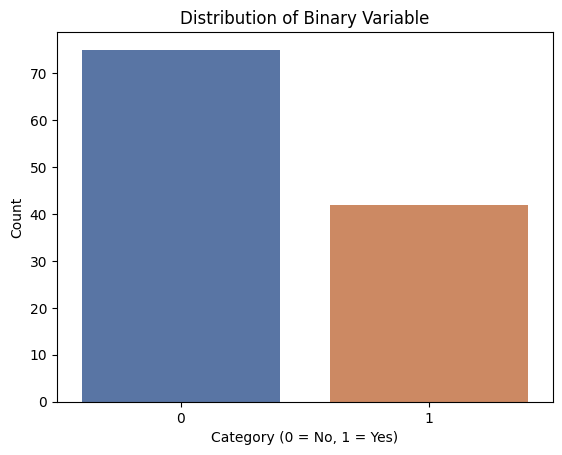

In [34]:
#  EDA
#  This is a problem of supervised binary classification
#  Let's take a look at the variables we are going to be working with

temp = training_data.copy()

y_train4 = temp['disorientation']  #  variable objetivo

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='disorientation', data=temp, hue= 'disorientation', legend=False, palette='deep')

plt.title('Distribution of Binary Variable')
plt.xlabel('Category (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

*The target variable is moderately imbalanced, with more cases of class 0 than class 1, although both classes are sufficiently represented.*

*Given that the distribution of the target variable is not balanced, accuracy may give a misleading impression of performance, since it can favour the majority class (**No disorientation**). The statement does not explicitly specify whether false negatives or false positives are more critical. However, since this is a medical context, it is generally more appropriate to place special attention on false negatives, as failing to detect a patient at risk could be potentially risky. For this reason, we will rely on the F1-score as the main evaluation metric, since it provides a better balance between precision and recall than accuracy alone.*

In [35]:
training_data.describe()

,fat,meat,stress,oxygen,sugar,disorientation
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,16.254162,176.681474,49.213944,85.179309,125.053504,0.358974
std,7.165509,68.762121,26.062191,7.481186,31.881868,0.481763
min,5.015620,55.713700,1.310820,70.160900,70.388900,0.000000
25%,10.163280,120.750600,27.643990,79.834700,95.986300,0.000000
50%,15.710540,178.445300,47.788680,84.290300,124.211000,0.000000
75%,21.824980,238.277500,72.866450,90.323600,151.983700,1.000000
max,29.641020,297.269600,98.154320,99.891200,179.745800,1.000000


*The predictors show different numerical scales, so feature standardization may be important for models sensitive to scale (logistic regression, SVM, k-NN, and neural networks).*

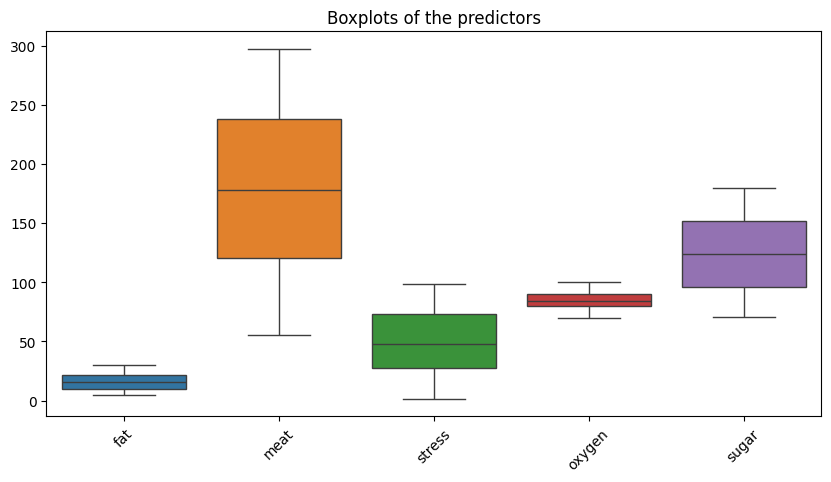

In [36]:
#  Boxplots
plt.figure(figsize=(10, 5))
sns.boxplot(data=training_data.drop(columns="disorientation"))
plt.title("Boxplots of the predictors")
plt.xticks(rotation=45)
plt.show()

*These boxplots show that the predictors are measured on clearly different numerical scales. This supports the use of a standardization forward. In addition, the boxplots allow us to inspect dispersion and possible outliers.*

*It seems also that the variables might be symmetrically distributed.*

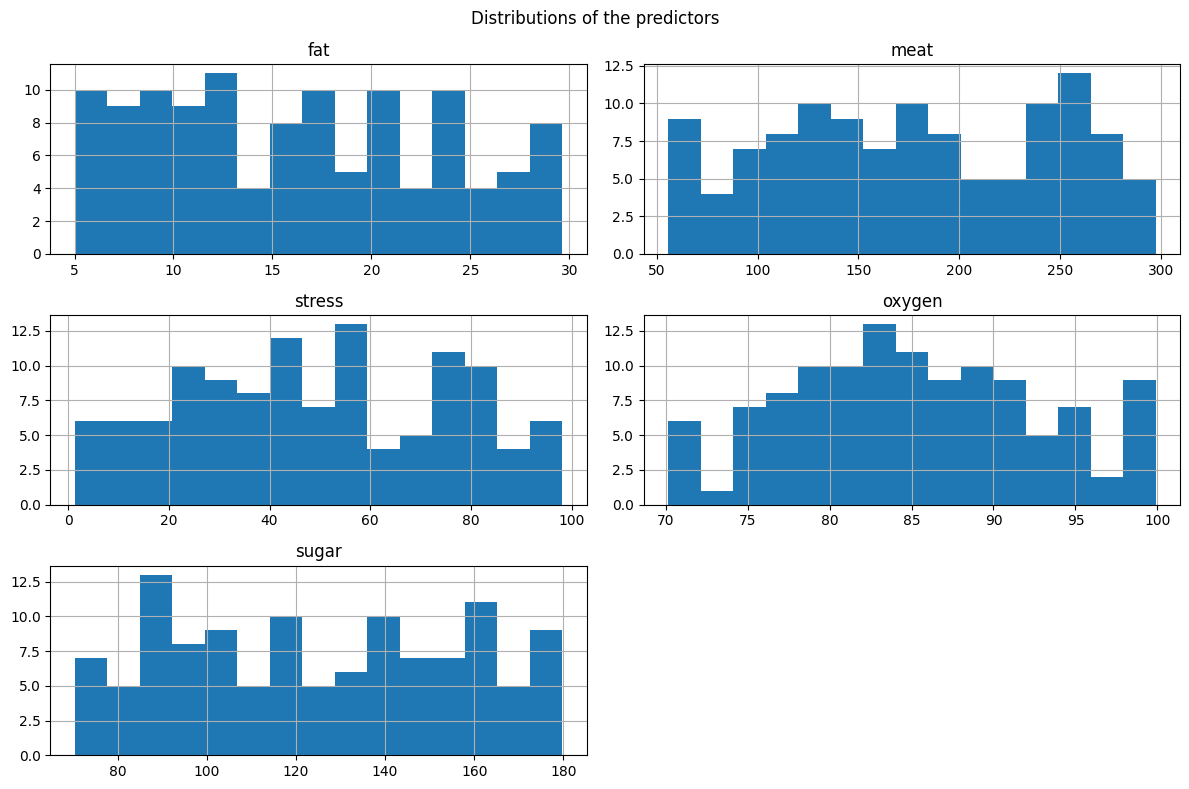

In [37]:
#  Distributions
training_data.drop(columns="disorientation").hist(figsize=(12, 8), bins=15)
plt.suptitle("Distributions of the predictors")
plt.tight_layout()
plt.show()

*The histograms suggest that the predictors do not show strong skewness or extreme concentration in a narrow range, although none of them appears perfectly Gaussian. Most variables are fairly spread across their respective ranges, and no severe distributional anomalies are evident from these plots alone*

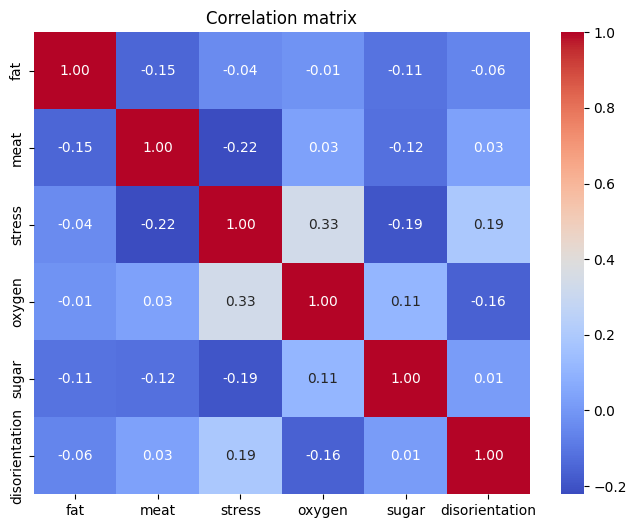

In [38]:
#  Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(training_data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

*The correlation matrix does not show strong linear relationships among the predictors, so there is no clear evidence of severe multicollinearity. In addition, none of the predictors appears to have an unusually strong linear correlation with the target.*

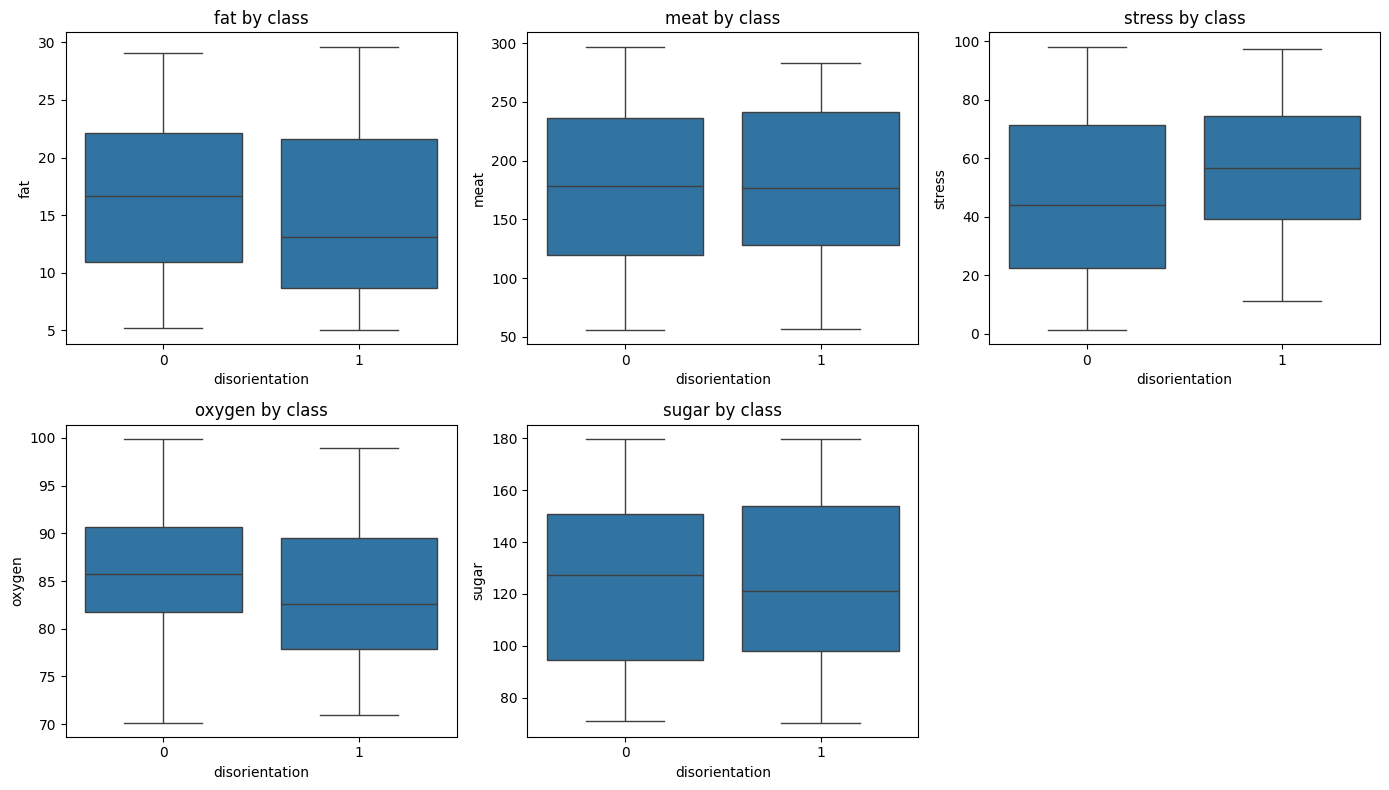

In [39]:
#  Boxplots by class
features = training_data.drop(columns="disorientation").columns

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=training_data, x="disorientation", y=col, ax=axes[i])
    axes[i].set_title(f"{col} by class")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

*These boxplots do not show strong separation between the two classes for most predictors, since the distributions overlap substantially. This suggests that no single variable is able to discriminate the target on its own in a very clear way.*

*However, some variables show slight differences between classes. In particular, **stress** tends to be somewhat higher for patients with disorientation, while **oxygen** appears slightly lower. The remaining variables show only modest differences in their central tendency and spread.*

*Overall, these plots suggest that the classification problem may require combining several predictors rather than relying on one strongly discriminative feature.*

In [40]:
training_data.isna().sum()

fat               0
meat              0
stress            0
oxygen            0
sugar             0
disorientation    0
dtype: int64

*Given that no obvious outliers or missing values were detected in the exploratory analysis, we conclude the EDA at this point.*

*The main issue to keep in mind for the modelling stage is that the predictors are measured on different numerical scales, so standardization will be necessary for models that are sensitive to feature magnitude.*

In [41]:
#  Data prep
X_train = training_data.drop('disorientation', axis=1)
X_val = val_data.drop('disorientation', axis=1)

y_train = training_data['disorientation']
y_val = val_data['disorientation']

### Logistic Regression

Best Hyperparameters: {'model__C': 1.0, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs', 'scaler': StandardScaler()}
Training accuracy: 0.6666666666666666
Validation accuracy: 0.6153846153846154
Training F1: 0.5806451612903226
Validation F1: 0.4

Validation classification report:

              precision    recall  f1-score   support

           0       0.66      0.79      0.72        24
           1       0.50      0.33      0.40        15

    accuracy                           0.62        39
   macro avg       0.58      0.56      0.56        39
weighted avg       0.60      0.62      0.60        39



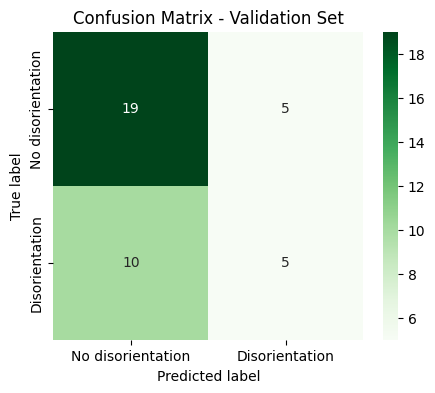

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

#  Pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000))
])

#  Parameter grid
param_grid = [
    {
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model__C': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0],
        'model__penalty': ['l2'],
        'model__solver': ['lbfgs'],
        'model__class_weight': [None, 'balanced']
    }
]

#  We use F1-score as the evaluation metric 
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='f1'
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

print("Best Hyperparameters:", grid_search.best_params_)
print("Training accuracy:", accuracy_score(y_train, train_preds))
print("Validation accuracy:", accuracy_score(y_val, val_preds))
print("Training F1:", f1_score(y_train, train_preds))
print("Validation F1:", f1_score(y_val, val_preds))

print("\nValidation classification report:\n")
print(classification_report(y_val, val_preds))

cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No disorientation', 'Disorientation'],
    yticklabels=['No disorientation', 'Disorientation']
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Validation Set')
plt.show()

*Although the number of false positives increases when optimizing for F1-score, the model now detects more true disorientation cases and reduces the number of false negatives. Since, in a medical setting, failing to identify a patient at risk is usually more problematic than issuing some extra false alarms, this trade-off is preferable.*

*However, logistic regression does not appear to be the most suitable model for this particular binary classification problem, as its overall performance remains limited even after adjusting the evaluation criterion and accounting for class imbalance.*

### SVM